# Zomato Bangalore Restaurants: What Is Linked to a High Rating?

**Dataset:** Zomato Bangalore restaurants (Kaggle), 51,717 rows and 17 columns.

**Question:** Which restaurant features (cost, table booking, online ordering, restaurant type, location and popularity) are associated with higher ratings?

**Approach:** data cleaning, exploratory analysis, controlling for cost and restaurant type, hypothesis tests, and a classification model to predict highly rated restaurants.

**Data note:** The same restaurant was listed many times (once per delivery zone), so duplicates were removed (12,499 restaurants left). Restaurants without a rating or a cost were also dropped, leaving 9,284.

In [1]:
mport numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

## DATA LOADING 

In [2]:
df = pd.read_csv('/kaggle/input/datasets/himanshupoddar/zomato-bangalore-restaurants/zomato.csv', encoding='latin-1')
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [3]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)

Shape: (51717, 17)

Columns: ['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']

Data Types:
 url                            object
address                        object
name                           object
online_order                   object
book_table                     object
rate                           object
votes                           int64
phone                          object
location                       object
rest_type                      object
dish_liked                     object
cuisines                       object
approx_cost(for two people)    object
reviews_list                   object
menu_item                      object
listed_in(type)                object
listed_in(city)                object
dtype: object


In [4]:
df.isnull().sum()

url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

## DATA CLEANING

In [5]:
df.duplicated(subset=['name', 'address']).sum()

np.int64(39218)

In [6]:
dup = df[df.duplicated(subset=['name', 'address'], keep=False)].sort_values('name')
dup[['name', 'address', 'listed_in(type)', 'listed_in(city)']].head(10)

,name,address,listed_in(type),listed_in(city)
49511,#FeelTheROLL,"Opposite Mantri Commercio, Outer Ring Road, De...",Delivery,Sarjapur Road
4321,#FeelTheROLL,"Opposite Mantri Commercio, Outer Ring Road, De...",Delivery,Bellandur
33627,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Delivery,Koramangala 6th Block
17166,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Dine-out,HSR
28099,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Delivery,Koramangala 4th Block
30833,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Delivery,Koramangala 5th Block
10182,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Delivery,BTM
29004,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Dine-out,Koramangala 4th Block
16606,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Delivery,HSR
36386,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Delivery,Koramangala 7th Block


In [7]:
print("Duplicates before:", df.duplicated(subset=['name', 'address']).sum())
df.drop_duplicates(subset=['name', 'address'], inplace=True)
print("Duplicates after:", df.duplicated(subset=['name', 'address']).sum())
print("Final shape:", df.shape)

Duplicates before: 39218
Duplicates after: 0
Final shape: (12499, 17)


In [8]:
df[~df['rate'].str.contains('/', na=False)]['rate'].value_counts()

rate
NEW    772
-        6
Name: count, dtype: int64

In [9]:
# Clean the rate column (e.g. "4.1/5" -> 4.1; "NEW" and "-" become NaN)
df['rate'] = df['rate'].str.split('/').str[0]
df['rate'] = pd.to_numeric(df['rate'], errors='coerce')

# Clean the cost column (e.g. "1,200" -> 1200)
df['approx_cost(for two people)'] = df['approx_cost(for two people)'].str.replace(',','')
df['approx_cost(for two people)'] = pd.to_numeric(df['approx_cost(for two people)'], errors='coerce')

# Describe before dropping nulls
df[['rate', 'votes', 'approx_cost(for two people)']].describe()

,rate,votes,approx_cost(for two people)
count,9316.000000,12499.000000,12440.00000
mean,3.625612,180.683815,487.20000
std,0.431536,591.711621,390.85198
min,1.800000,0.000000,40.00000
25%,3.300000,0.000000,250.00000
50%,3.700000,24.000000,400.00000
75%,3.900000,120.000000,600.00000
max,4.900000,16345.000000,6000.00000


In [10]:
df.dropna(subset=['rate', 'approx_cost(for two people)'], inplace=True)
print("After cleaning shape:", df.shape)

After cleaning shape: (9284, 17)


## DESCRIPTIVE STATISTICS AND DISTRIBUTION 

In [11]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 9284 entries, 0 to 51677
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          9284 non-null   object 
 1   address                      9284 non-null   object 
 2   name                         9284 non-null   object 
 3   online_order                 9284 non-null   object 
 4   book_table                   9284 non-null   object 
 5   rate                         9284 non-null   float64
 6   votes                        9284 non-null   int64  
 7   phone                        9147 non-null   object 
 8   location                     9284 non-null   object 
 9   rest_type                    9247 non-null   object 
 10  dish_liked                   4562 non-null   object 
 11  cuisines                     9281 non-null   object 
 12  approx_cost(for two people)  9284 non-null   float64
 13  reviews_list          

,rate,votes,approx_cost(for two people)
count,9284.000000,9284.000000,9284.000000
mean,3.625959,242.419000,536.684511
std,0.431335,674.920665,426.150625
min,1.800000,0.000000,40.000000
25%,3.300000,16.000000,300.000000
50%,3.700000,53.000000,400.000000
75%,3.900000,191.000000,600.000000
max,4.900000,16345.000000,6000.000000


In [12]:
# Mean, Median, Mode
print("=== MEAN ===")
print(df[['votes', 'rate', 'approx_cost(for two people)']].mean())

print("\n=== MEDIAN ===")
print(df[['votes', 'rate', 'approx_cost(for two people)']].median())

print("\n=== MODE ===")
print(df[['votes', 'rate', 'approx_cost(for two people)']].mode().iloc[0])

print("\n=== STANDARD DEVIATION ===")
print(df[['votes', 'rate', 'approx_cost(for two people)']].std())

print("\n=== VARIANCE ===")
print(df[['votes', 'rate', 'approx_cost(for two people)']].var())

=== MEAN ===
votes                          242.419000
rate                             3.625959
approx_cost(for two people)    536.684511
dtype: float64

=== MEDIAN ===
votes                           53.0
rate                             3.7
approx_cost(for two people)    400.0
dtype: float64

=== MODE ===
votes                            4.0
rate                             3.7
approx_cost(for two people)    400.0
Name: 0, dtype: float64

=== STANDARD DEVIATION ===
votes                          674.920665
rate                             0.431335
approx_cost(for two people)    426.150625
dtype: float64

=== VARIANCE ===
votes                          455517.903704
rate                                0.186050
approx_cost(for two people)    181604.354943
dtype: float64


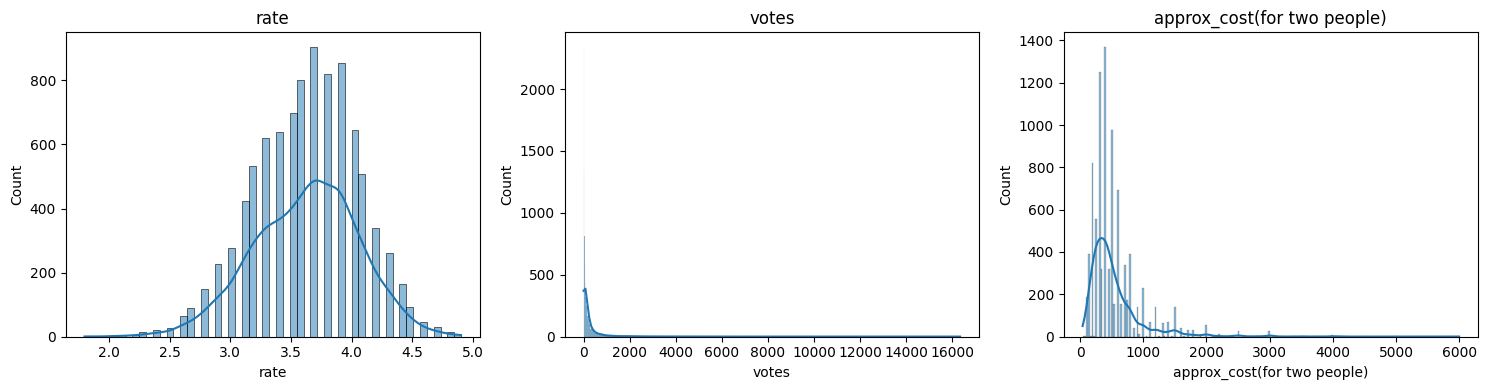

rate                          -0.208534
votes                          9.076897
approx_cost(for two people)    3.212611
dtype: float64


In [13]:
cols = ['rate', 'votes', 'approx_cost(for two people)']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

print(df[cols].skew())

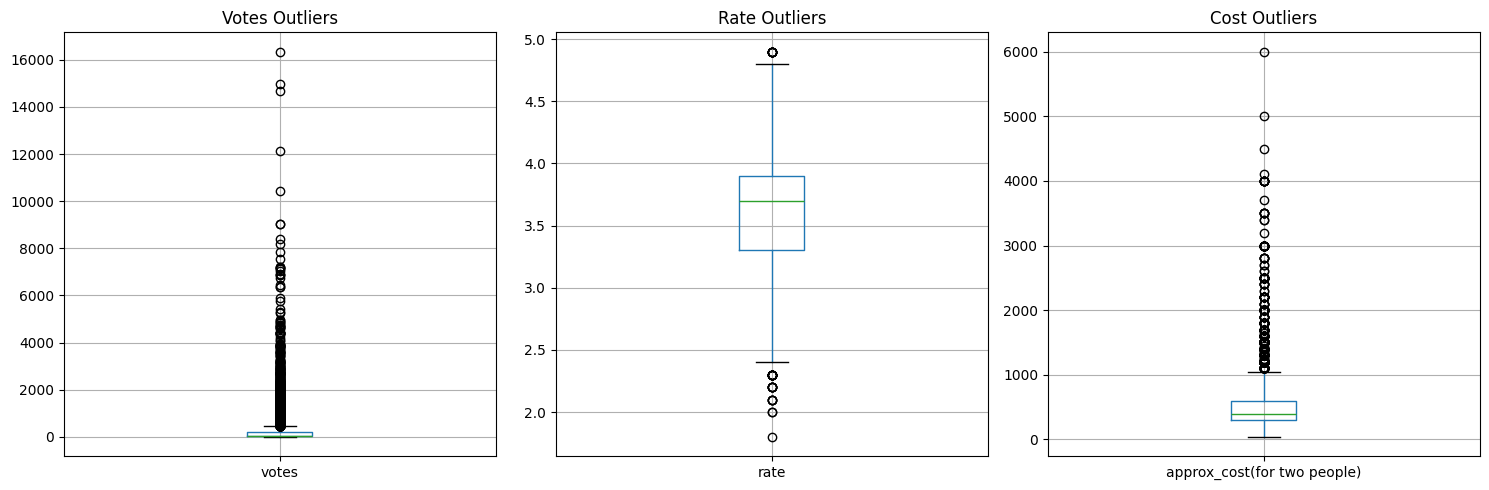

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

df.boxplot(column='votes', ax=axes[0])
axes[0].set_title('Votes Outliers')

df.boxplot(column='rate', ax=axes[1])
axes[1].set_title('Rate Outliers')

df.boxplot(column='approx_cost(for two people)', ax=axes[2])
axes[2].set_title('Cost Outliers')

plt.tight_layout()
plt.show()

In [15]:
df['votes_log'] = np.log1p(df['votes'])
df['cost_log'] = np.log1p(df['approx_cost(for two people)'])

print(df[['votes_log', 'cost_log']].skew())

votes_log    0.396003
cost_log     0.282285
dtype: float64


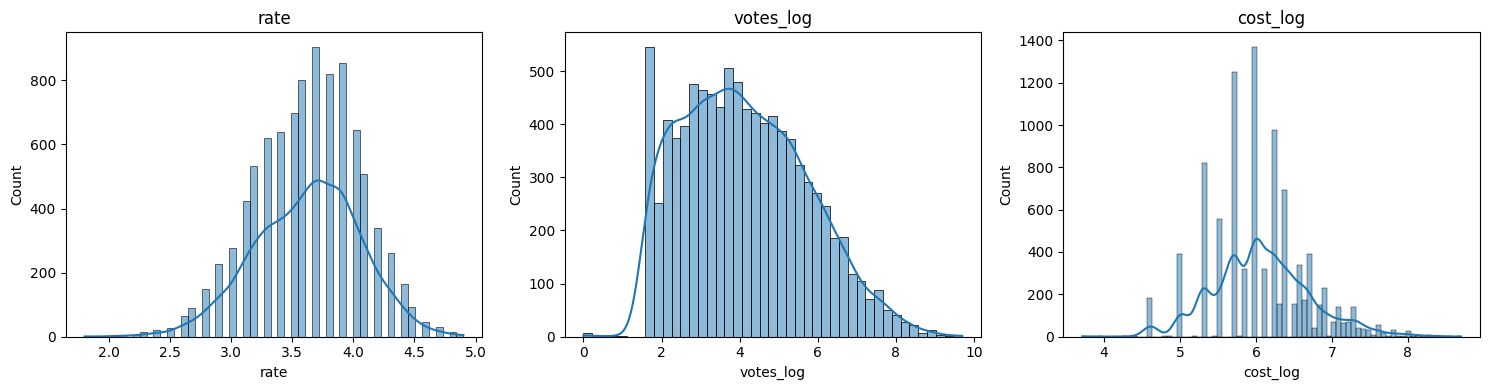

rate        -0.208534
votes_log    0.396003
cost_log     0.282285
dtype: float64


In [16]:
cols = ['rate', 'votes_log', 'cost_log']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

print(df[cols].skew())

## CORRELATION

In [17]:
# Covariance
print("=== COVARIANCE ===")
print(df[['votes', 'rate', 'approx_cost(for two people)']].cov())

# Correlation (Pearson)
print("\n=== CORRELATION ===")
print(df[['votes', 'rate', 'approx_cost(for two people)']].corr())

=== COVARIANCE ===
                                     votes        rate  \
votes                        455517.903704  116.484684   
rate                            116.484684    0.186050   
approx_cost(for two people)   97732.477028   60.152303   

                             approx_cost(for two people)  
votes                                       97732.477028  
rate                                           60.152303  
approx_cost(for two people)                181604.354943  

=== CORRELATION ===
                               votes      rate  approx_cost(for two people)
votes                        1.00000  0.400130                     0.339800
rate                         0.40013  1.000000                     0.327246
approx_cost(for two people)  0.33980  0.327246                     1.000000


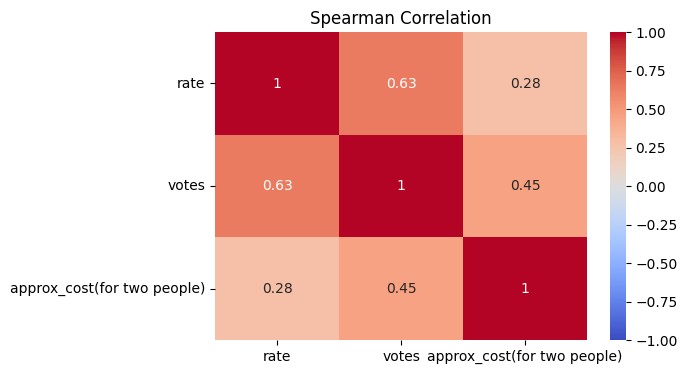

In [18]:
cols = ['rate', 'votes', 'approx_cost(for two people)']
corr = df[cols].corr(method='spearman')

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman Correlation')
plt.show()

## RATING BY LOCATION

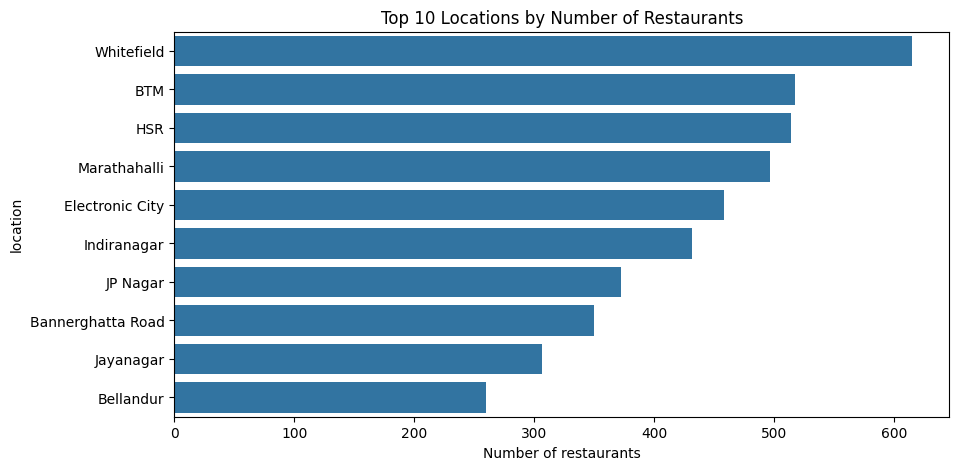

In [19]:
top_loc = df['location'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_loc.values, y=top_loc.index)
plt.title('Top 10 Locations by Number of Restaurants')
plt.xlabel('Number of restaurants')
plt.show()

In [20]:
df[df['location'].isin(top_loc.index)].groupby('location')['rate'].agg(['count','mean','median']).sort_values('mean', ascending=False)

,count,mean,median
location,,,
Indiranagar,431,3.784687,3.90
Jayanagar,306,3.760784,3.80
HSR,514,3.642218,3.70
JP Nagar,372,3.634677,3.70
Whitefield,615,3.599187,3.60
BTM,517,3.556093,3.60
Marathahalli,496,3.530040,3.60
Bellandur,260,3.491538,3.55
Bannerghatta Road,350,3.476000,3.50


## ONLINE ORDER AND TABLE BOOKING 

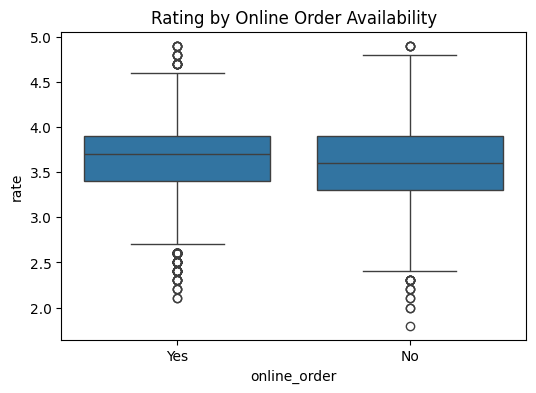

In [21]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='online_order', y='rate', data=df)
plt.title('Rating by Online Order Availability')
plt.show()

In [22]:
print(df.groupby('book_table')['rate'].agg(['count','mean','median']).sort_values('mean', ascending=False))

            count      mean  median
book_table                         
Yes           923  4.114735     4.1
No           8361  3.572001     3.6


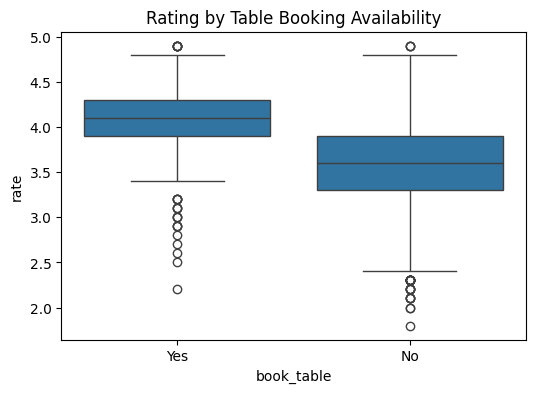

In [23]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='book_table', y='rate', data=df)
plt.title('Rating by Table Booking Availability')
plt.show()

## CONTROLLING FOR COST AND RESTAURANT TYPE

In [24]:
print(df.groupby('book_table')['approx_cost(for two people)'].agg(['count','mean','median']).sort_values('mean', ascending=False))

            count         mean  median
book_table                            
Yes           923  1305.633803  1200.0
No           8361   451.797512   400.0


In [25]:
df['cost_band'] = pd.cut(
    df['approx_cost(for two people)'],
    bins=[0, 300, 600, 1000, 6000],
    labels=['Budget (<=300)', 'Mid (301-600)', 'Upper-mid (601-1000)', 'Premium (>1000)']
)
print(df['cost_band'].value_counts())

cost_band
Mid (301-600)           3831
Budget (<=300)          3214
Upper-mid (601-1000)    1474
Premium (>1000)          765
Name: count, dtype: int64


In [26]:
print(df.groupby(['cost_band', 'book_table'], observed=True)['rate'].agg(['count', 'mean', 'median']))

                                 count      mean  median
cost_band            book_table                         
Budget (<=300)       No           3208  3.543423    3.50
                     Yes             6  3.850000    3.85
Mid (301-600)        No           3763  3.558942    3.60
                     Yes            68  3.958824    4.00
Upper-mid (601-1000) No           1152  3.628385    3.70
                     Yes           322  4.011801    4.00
Premium (>1000)      No            238  3.890756    3.90
                     Yes           527  4.200759    4.20


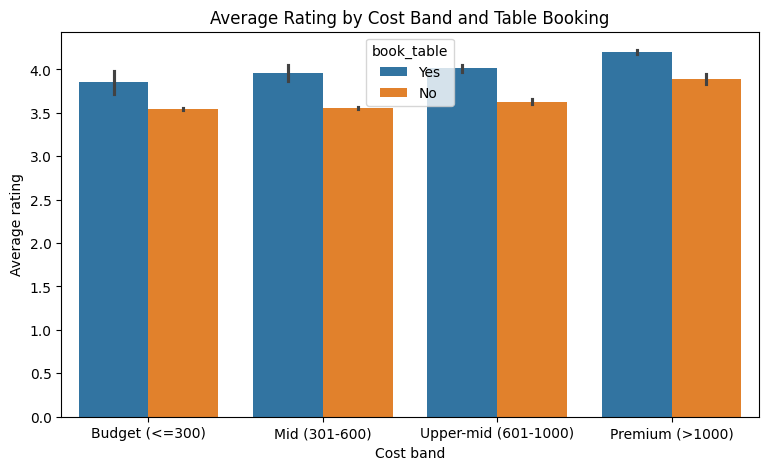

In [27]:
plt.figure(figsize=(9, 5))
sns.barplot(x='cost_band', y='rate', hue='book_table', data=df)
plt.title('Average Rating by Cost Band and Table Booking')
plt.xlabel('Cost band')
plt.ylabel('Average rating')
plt.show()

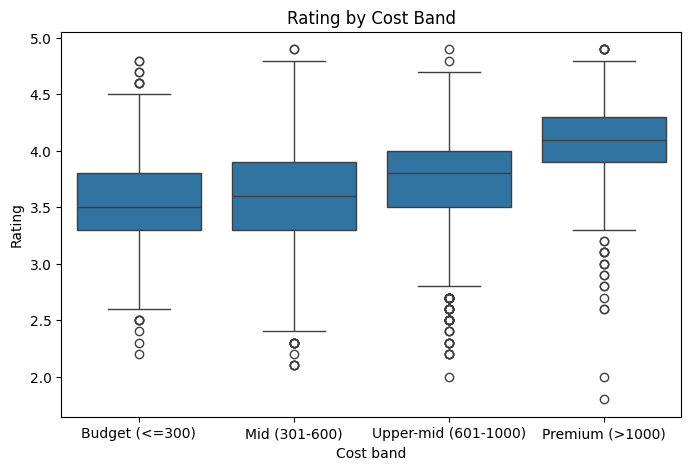

In [28]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='cost_band', y='rate', data=df)
plt.title('Rating by Cost Band')
plt.xlabel('Cost band')
plt.ylabel('Rating')
plt.show()

In [29]:
print(df.groupby(['cost_band', 'online_order'], observed=True)['rate'].agg(['count', 'mean', 'median']))

                                   count      mean  median
cost_band            online_order                         
Budget (<=300)       No             1367  3.482370     3.5
                     Yes            1847  3.589605     3.6
Mid (301-600)        No             1187  3.482645     3.5
                     Yes            2644  3.603480     3.7
Upper-mid (601-1000) No              514  3.644553     3.7
                     Yes             960  3.748333     3.9
Premium (>1000)      No              511  4.069276     4.1
                     Yes             254  4.174803     4.2


In [30]:
top_types = df['rest_type'].value_counts().head(8)
print(top_types)

rest_type
Quick Bites           3436
Casual Dining         2027
Delivery               534
Cafe                   492
Dessert Parlor         454
Takeaway, Delivery     431
Bakery                 196
Beverage Shop          175
Name: count, dtype: int64


In [31]:
top_df = df[df['rest_type'].isin(top_types.index)]
print(top_df.groupby('rest_type')['rate'].agg(['count', 'mean', 'median']).sort_values('mean', ascending=False))

                    count      mean  median
rest_type                                  
Dessert Parlor        454  3.809912     3.9
Cafe                  492  3.742480     3.8
Casual Dining        2027  3.679576     3.7
Beverage Shop         175  3.621714     3.6
Bakery                196  3.597449     3.6
Delivery              534  3.558614     3.6
Quick Bites          3436  3.520518     3.5
Takeaway, Delivery    431  3.511833     3.5


In [32]:
share = top_df.groupby('rest_type')['book_table'].apply(lambda s: (s == 'Yes').mean() * 100)
print(share.sort_values(ascending=False).round(1))

rest_type
Casual Dining         21.5
Cafe                  11.2
Quick Bites            0.5
Takeaway, Delivery     0.2
Bakery                 0.0
Beverage Shop          0.0
Dessert Parlor         0.0
Delivery               0.0
Name: book_table, dtype: float64


In [33]:
print(top_df.groupby(['rest_type', 'book_table'])['rate'].agg(['count', 'mean']))

                               count      mean
rest_type          book_table                 
Bakery             No            196  3.597449
Beverage Shop      No            175  3.621714
Cafe               No            437  3.699085
                   Yes            55  4.087273
Casual Dining      No           1591  3.573350
                   Yes           436  4.067202
Delivery           No            534  3.558614
Dessert Parlor     No            454  3.809912
Quick Bites        No           3419  3.518982
                   Yes            17  3.829412
Takeaway, Delivery No            430  3.510465
                   Yes             1  4.100000


## HYPOTHESIS TESTS

In [34]:
for col in ['online_order', 'book_table']:
    yes = df[df[col] == 'Yes']['rate']
    no = df[df[col] == 'No']['rate']
    stat, p = mannwhitneyu(yes, no, alternative='two-sided')
    print(col)
    print("  Yes median:", yes.median(), "| No median:", no.median())
    print("  p-value:", p)

online_order
  Yes median: 3.7 | No median: 3.6
  p-value: 8.292530963658107e-17
book_table
  Yes median: 4.1 | No median: 3.6
  p-value: 5.469506515878554e-289


## PREDICTIVE MODELING

In [35]:
# Target: is the restaurant highly rated (4.0 or above)?
df['high_rated'] = (df['rate'] >= 4.0).astype(int)

print(df['high_rated'].value_counts())
print(df['high_rated'].value_counts(normalize=True).round(3))

high_rated
0    7175
1    2109
Name: count, dtype: int64
high_rated
0    0.773
1    0.227
Name: proportion, dtype: float64


In [36]:
# Encode Yes/No columns as 1/0
df['online_order_num'] = (df['online_order'] == 'Yes').astype(int)
df['book_table_num'] = (df['book_table'] == 'Yes').astype(int)

# Group rare restaurant types into 'Other'
model_types = df['rest_type'].value_counts().head(6).index
df['rest_type_grp'] = df['rest_type'].where(df['rest_type'].isin(model_types), 'Other')

# Build the feature table (X) and the target (y)
features = ['votes_log', 'cost_log', 'online_order_num', 'book_table_num', 'rest_type_grp']
X = pd.get_dummies(df[features], columns=['rest_type_grp'], drop_first=True, dtype=int)
y = df['high_rated']

print(X.shape)
print(X.columns.tolist())

(9284, 10)
['votes_log', 'cost_log', 'online_order_num', 'book_table_num', 'rest_type_grp_Casual Dining', 'rest_type_grp_Delivery', 'rest_type_grp_Dessert Parlor', 'rest_type_grp_Other', 'rest_type_grp_Quick Bites', 'rest_type_grp_Takeaway, Delivery']


In [37]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

# Baseline: always predict the most common class (0 = Not High)
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
print("Baseline accuracy:", round(accuracy_score(y_test, baseline.predict(X_test)), 3))

(7427, 10) (1857, 10)
0.227 0.227
Baseline accuracy: 0.773


In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

rf = RandomForestClassifier(
    n_estimators=200, max_depth=8, class_weight='balanced', random_state=42
)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print("Train accuracy:", round(rf.score(X_train, y_train), 3))
print("Test accuracy:", round(rf.score(X_test, y_test), 3))
print()
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Train accuracy: 0.839
Test accuracy: 0.82

              precision    recall  f1-score   support

           0       0.93      0.82      0.88      1435
           1       0.57      0.80      0.67       422

    accuracy                           0.82      1857
   macro avg       0.75      0.81      0.77      1857
weighted avg       0.85      0.82      0.83      1857

[[1183  252]
 [  83  339]]


votes_log                           0.375
cost_log                            0.015
rest_type_grp_Casual Dining         0.015
book_table_num                      0.006
online_order_num                    0.005
rest_type_grp_Quick Bites           0.005
rest_type_grp_Dessert Parlor        0.002
rest_type_grp_Delivery              0.001
rest_type_grp_Takeaway, Delivery    0.000
rest_type_grp_Other                -0.001
dtype: float64


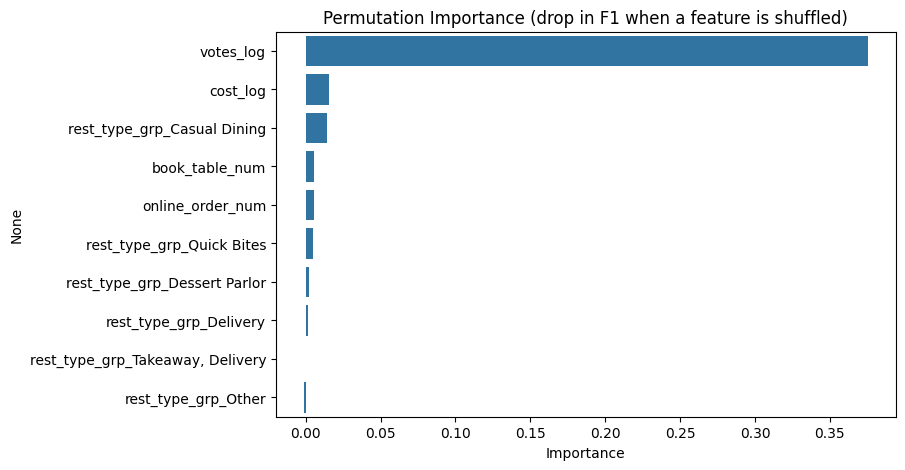

In [39]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=42, scoring='f1'
)

imp = pd.Series(result.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp.round(3))

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index)
plt.title('Permutation Importance (drop in F1 when a feature is shuffled)')
plt.xlabel('Importance')
plt.show()

In [40]:
# Same split as before, just without votes_log
X_train2 = X_train.drop(columns=['votes_log'])
X_test2 = X_test.drop(columns=['votes_log'])

rf2 = RandomForestClassifier(
    n_estimators=200, max_depth=8, class_weight='balanced', random_state=42
)
rf2.fit(X_train2, y_train)
y_pred2 = rf2.predict(X_test2)

print("Test accuracy (without votes):", round(rf2.score(X_test2, y_test), 3))
print(classification_report(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))

Test accuracy (without votes): 0.763
              precision    recall  f1-score   support

           0       0.88      0.80      0.84      1435
           1       0.48      0.62      0.54       422

    accuracy                           0.76      1857
   macro avg       0.68      0.71      0.69      1857
weighted avg       0.79      0.76      0.77      1857

[[1155  280]
 [ 160  262]]


In [41]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_cv = RandomForestClassifier(
    n_estimators=200, max_depth=8, class_weight='balanced', random_state=42
)

scores_with = cross_val_score(rf_cv, X, y, cv=cv, scoring='f1')
scores_without = cross_val_score(rf_cv, X.drop(columns=['votes_log']), y, cv=cv, scoring='f1')

print("With votes   :", scores_with.round(3), "| mean:", scores_with.mean().round(3))
print("Without votes:", scores_without.round(3), "| mean:", scores_without.mean().round(3))

With votes   : [0.669 0.693 0.667 0.687 0.667] | mean: 0.677
Without votes: [0.547 0.579 0.528 0.55  0.545] | mean: 0.55


## Key Findings, Conclusion and Limitations

**Data**
- Duplicates removed: 51,717 listings became 12,499 restaurants. After dropping restaurants with no rating or cost, 9,284 remained.
- `votes` is highly skewed (mean 242 vs median 53), so a log transform was used instead of deleting outliers.

**What is linked to ratings**
- Popularity is most strongly linked to rating: votes and rating have a Spearman correlation of 0.63, while cost and rating have only 0.28.
- Location: Indiranagar (3.78) and Jayanagar (3.76) have the highest average ratings among the top 10 areas, but the whole range is only about 0.3 points. Whitefield has the most restaurants (615) but ranks fifth on rating.
- Table booking: restaurants offering it are rated higher (4.11 vs 3.57), but they are also about three times more expensive (median ₹1,200 vs ₹400). Within the same cost band, the gap shrinks to about 0.3-0.4 points but does not disappear. It also remains inside Casual Dining and Cafes.
- Online ordering: the gap is small (median 3.7 vs 3.6), though it holds at about 0.1 points in every cost band. The Mann-Whitney test is significant for both features, but significance does not mean a large effect, and online ordering has a small one.

**Prediction (highly rated = rating of 4.0 or above, 22.7% of restaurants)**
- A Random Forest reached an F1 of 0.67 on the high-rated class (recall 0.80, precision 0.57). 5-fold cross-validation gave a similar mean F1 of 0.68.
- Without `votes`, the F1 dropped to about 0.55. So most of the predictive power comes from popularity, and cost, type, table booking and online ordering explain only part of a restaurant's rating.

**Conclusion**
Higher-rated restaurants tend to be more popular, more expensive, and offer table booking, but these features explain only part of the rating.

**Limitations**
- These are associations, not causes. Food quality, service and ambience are not in the data.
- `votes` is collected after a restaurant becomes popular, so it partly reflects the rating itself.
- Only 6 budget restaurants offer table booking, so that group was ignored.
- The model was evaluated on one data source and a small set of features, with no hyperparameter tuning.